In this notebook we will do all the processing for the camera to detect all the keys and transform them into joint angles for our robot

## Step 1

Calibrate the camera with the pictures that we have already taken

In [23]:
import numpy as np
import cv2
import glob
import matplotlib.pyplot as plt

In [24]:
# Implement the number of vertical and horizontal corners
nb_vertical = 9      # CHANGE: our board has 9x6 inner corners (course board was 6x7)
nb_horizontal = 6
square_size = 25.0   # CHANGE: mm, measured with the ruler -> tvecs in mm (K is the same either way)

# prepare object points, like (0,0,0), (25,0,0), (50,0,0) ...
objp = np.zeros((nb_horizontal*nb_vertical,3), np.float32)
objp[:,:2] = np.mgrid[0:nb_vertical,0:nb_horizontal].T.reshape(-1,2) * square_size

# Arrays to store object points and image points from all the images.
objpoints = [] # 3d point in real world space
imgpoints = [] # 2d points in image plane.

images = glob.glob('calib_images/*.png')   # CHANGE: our folder
assert images

# CHANGE: sub-pixel refinement of the corners (more accurate calibration)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

for fname in images:
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(image = gray, patternSize=(nb_vertical, nb_horizontal))

    # If found, add object points, image points (after refining them)
    if ret == True:
        objpoints.append(objp)

        corners = cv2.cornerSubPix(gray, corners, (11,11), (-1,-1), criteria)   # CHANGE
        imgpoints.append(corners)

        # Draw and display the corners
        img = cv2.drawChessboardCorners(img, (nb_vertical,nb_horizontal), corners,ret)
    else:
        print("Corners NOT found in", fname)   # CHANGE: know which images fail

cv2.destroyAllWindows()
print(f"Corners found in {len(objpoints)}/{len(images)} images")

Corners found in 19/19 images


Using the extracted corners we can obtain a camera matrix that contains the information needed to undistort images

In [25]:
# CHANGE: CALIB_FIX_K3 -> distortion model only k1, k2 (+ p1, p2), like Lecture 4:
#         x_hat = x (1 + k1 r^2 + k2 r^4)   -> avoids the huge k2/k3 we got before
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None,
                                                   flags=cv2.CALIB_FIX_K3)

np.set_printoptions(precision=4, suppress=True)
print("RMS reprojection error [px]:", ret)     # CHANGE: check quality (< ~1 px is good)
print("mtx =\n", mtx)
print("dist [k1, k2, p1, p2, k3] =", dist.ravel())

img = cv2.imread(images[0])                   # CHANGE: any image, no hardcoded name
h,  w = img.shape[:2]
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx,dist,(w,h),1,(w,h))

RMS reprojection error [px]: 3.2045378524808137
mtx =
 [[671.4318   0.     295.8261]
 [  0.     670.326  209.3136]
 [  0.       0.       1.    ]]
dist [k1, k2, p1, p2, k3] = [-0.0256  0.0927 -0.0046 -0.0201  0.    ]


The last step is to actually undistort an image:

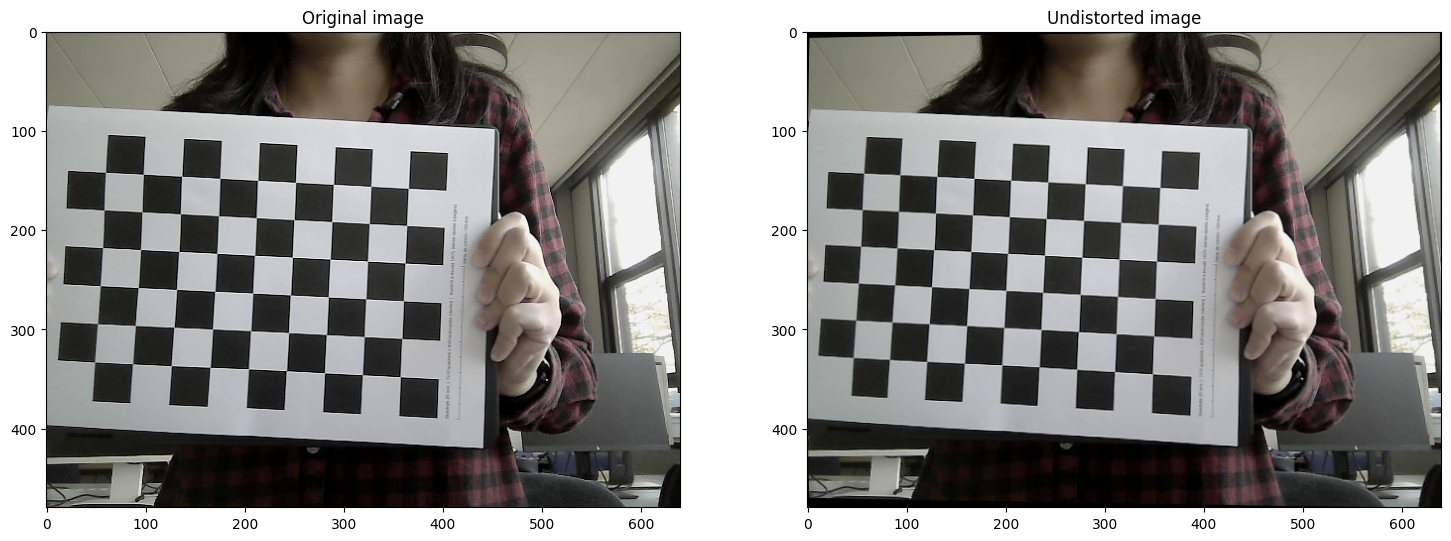

In [26]:
# undistort
dst = cv2.undistort(img, mtx, dist, None, newcameramtx)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18,18))
ax[0].imshow(img[...,[2,1,0]])
ax[0].set_title('Original image')
ax[1].imshow(dst[...,[2,1,0]])
ax[1].set_title('Undistorted image')
plt.show()

## Step 2
 
Now that we have calibrated the camera we can proceed to undistort our keyboard image

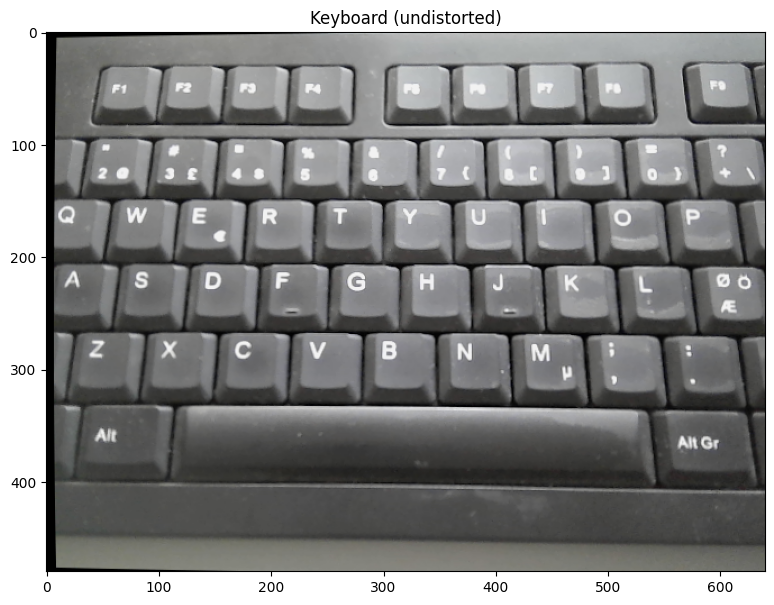

In [35]:
kb_raw = cv2.imread("keyboard_images/keyboard_20261029_103154_raw.png")   # <-- your file
kb = cv2.undistort(kb_raw, mtx, dist, None, mtx)
kb_gray = cv2.cvtColor(kb, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 7))
plt.imshow(kb[...,[2,1,0]])
plt.title("Keyboard (undistorted)")
plt.show()

Now we will do the template matching for finding where are the keys that interest us

In [36]:
templates = {}

# Strings (with quotes): they are the file names in templates/
LETTERS = ["H", "E", "L", "O", "W", "R", "D", "SPACE"]

for letter in LETTERS:
    t = cv2.imread(f"templates/{letter}.png", cv2.IMREAD_GRAYSCALE)
    if t is not None:
        templates[letter] = t
    else:
        print("Template NOT found:", letter)   # imread returns None if the file is missing
print({k: v.shape for k, v in templates.items()})


{'H': (59, 70), 'E': (64, 69), 'L': (69, 87), 'O': (67, 79), 'W': (72, 71), 'R': (65, 76), 'D': (69, 81), 'SPACE': (96, 457)}


<Figure size 640x480 with 0 Axes>

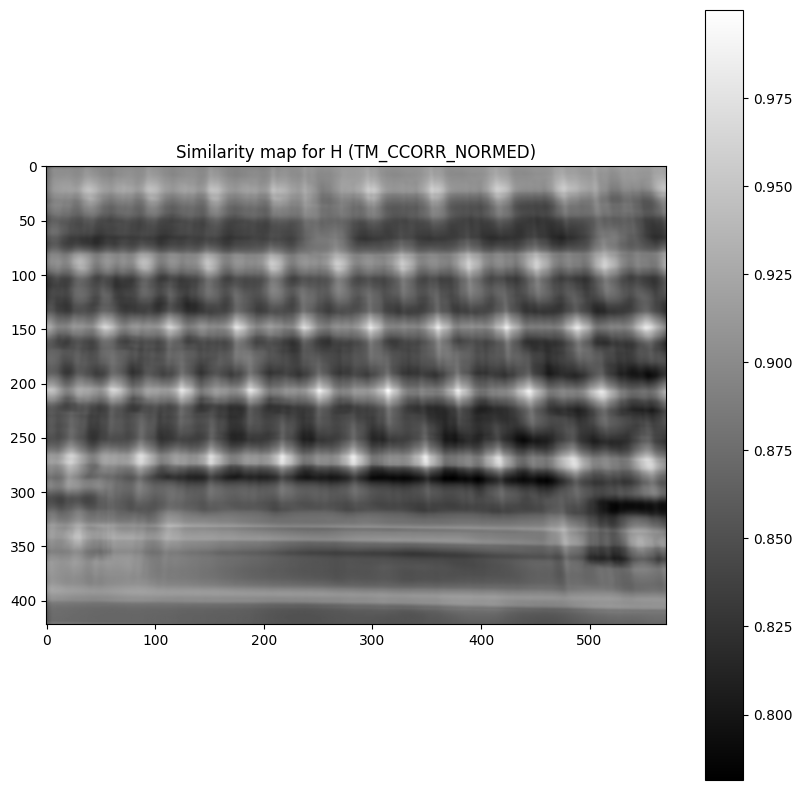

In [37]:
plt.gray()

# Keyboard image in RGB (for drawing) and grayscale (for matching)
kb_rgb = cv2.cvtColor(kb, cv2.COLOR_BGR2RGB)
kb_gray = cv2.cvtColor(kb, cv2.COLOR_BGR2GRAY)

# Start with one letter to see what happens
template = templates["H"]

# Slide the template over every position of the image and compute the
# similarity score -> 2D similarity map (slightly smaller than the image)
res = cv2.matchTemplate(kb_gray, template, cv2.TM_CCORR_NORMED)

plt.figure(figsize=(10,10))
plt.imshow(res, 'gray')
plt.colorbar()
plt.title("Similarity map for H (TM_CCORR_NORMED)")
plt.show()

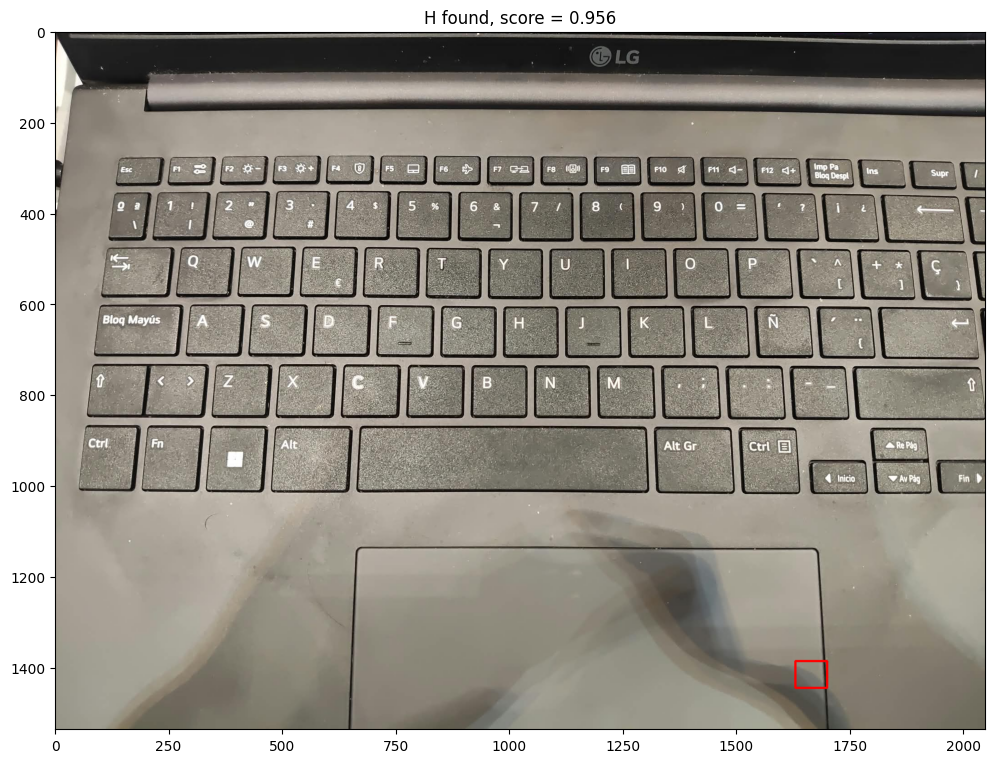

In [34]:
# Best match = maximum of the similarity map (higher = better for CCORR_NORMED)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

top_left = max_loc
bottom_right = (top_left[0] + template.shape[1], top_left[1] + template.shape[0])

h_key = cv2.rectangle(kb_rgb.copy(), top_left, bottom_right, (255,0,0), 3)

plt.figure(figsize=(12,12))
plt.imshow(h_key)
plt.title(f"H found, score = {max_val:.3f}")
plt.show()

H      center = ( 349.0,  236.5)   score = 1.000
E      center = ( 147.5,  176.0)   score = 1.000
L      center = ( 544.5,  238.5)   score = 1.000
O      center = ( 524.5,  178.5)   score = 1.000
W      center = (  88.5,  178.0)   score = 1.000
R      center = ( 210.0,  176.5)   score = 1.000
D      center = ( 157.5,  233.5)   score = 1.000
SPACE  center = ( 325.5,  367.0)   score = 1.000


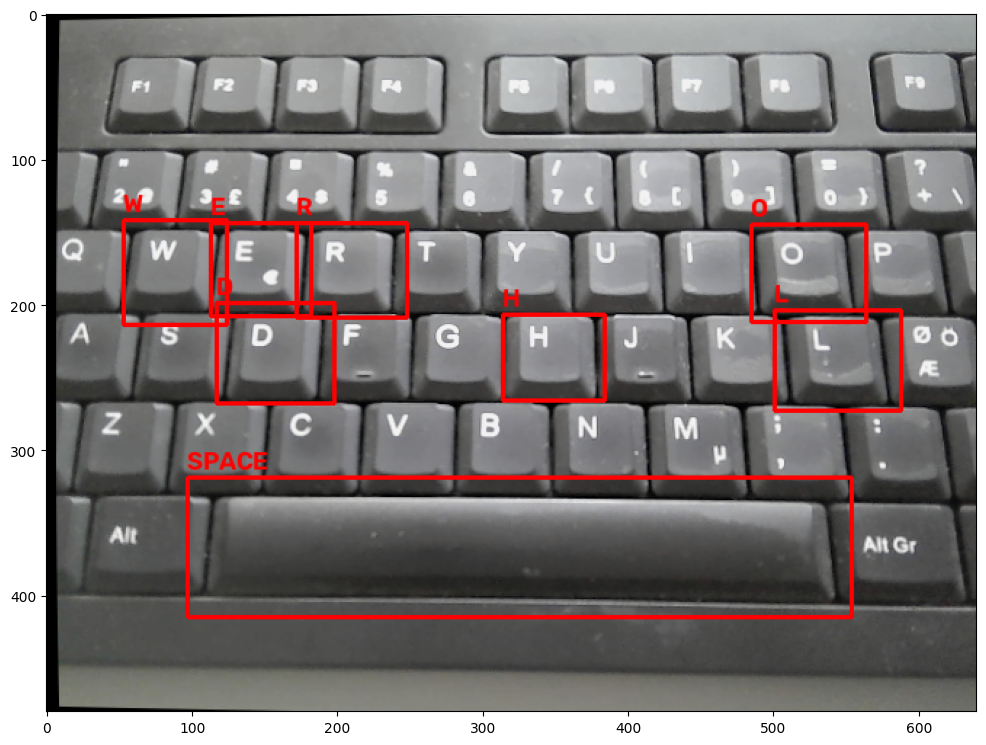

In [13]:
# Same as above, for every template.
# We also keep the CENTER of each key (u, v) in pixels -> input of Step 3.
# max_loc is the top-left corner, so center = top-left + (w/2, h/2)
key_px = {}
result = kb_rgb.copy()

for letter, template in templates.items():
    res = cv2.matchTemplate(kb_gray, template, cv2.TM_CCORR_NORMED)
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

    h, w = template.shape
    top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    u, v = top_left[0] + w/2, top_left[1] + h/2
    key_px[letter] = (u, v)

    cv2.rectangle(result, top_left, bottom_right, (255,0,0), 2)
    cv2.putText(result, letter, (top_left[0], top_left[1]-5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,0,0), 2)
    print(f"{letter:6s} center = ({u:6.1f}, {v:6.1f})   score = {max_val:.3f}")

plt.figure(figsize=(12,12))
plt.imshow(result)
plt.show()

## Step 3

Now that we have the positions of the keys from our picture, we will translate those postions from pixels to a 3D camera point.

In [39]:
o_r, o_c = mtx[0, 2], mtx[1, 2]     # image center (pixels)
f_x, f_y = mtx[0, 0], mtx[1, 1]     # focal length (pixels)

key_xz = {}
for letter, (r, c) in key_px.items():
    x_z = (r - o_r) / f_x            # x/z
    y_z = (c - o_c) / f_y            # y/z
    key_xz[letter] = (x_z, y_z)
    print(f"{letter:6s} (r, c) = ({r:6.1f}, {c:6.1f})  ->  x/z = {x_z:.3f},  y/z = {y_z:.3f}")

H      (r, c) = ( 349.0,  236.5)  ->  x/z = 0.079,  y/z = 0.041
E      (r, c) = ( 147.5,  176.0)  ->  x/z = -0.221,  y/z = -0.050
L      (r, c) = ( 544.5,  238.5)  ->  x/z = 0.370,  y/z = 0.044
O      (r, c) = ( 524.5,  178.5)  ->  x/z = 0.341,  y/z = -0.046
W      (r, c) = (  88.5,  178.0)  ->  x/z = -0.309,  y/z = -0.047
R      (r, c) = ( 210.0,  176.5)  ->  x/z = -0.128,  y/z = -0.049
D      (r, c) = ( 157.5,  233.5)  ->  x/z = -0.206,  y/z = 0.036
SPACE  (r, c) = ( 325.5,  367.0)  ->  x/z = 0.044,  y/z = 0.235


In [40]:
from kinematics import direct_kinematics
q_obs = np.array([0, 0, 0, 0])   # <-- joint angles where the photo was taken (rad)
T05 = direct_kinematics(q_obs)   # must return the 4x4 matrix of the CAMERA (frame 5)

o05 = T05[:3, 3]                 # camera position in base frame
R05 = T05[:3, :3]                # camera orientation

# Where does the camera look? We assume it looks along x5 (Figure 1)
# -> 1st column of R05 = x5 written in base coordinates
look_dir = R05[:, 0]
print("camera position [mm]:", o05.round(1))
print("camera looks along:", look_dir.round(3), " (want ~ [0, 0, -1] = straight down)")

Z_KEYS = 25.0                    # <-- height of the key tops above the base frame (mm, ruler)
z = o05[2] - Z_KEYS
print(f"z (camera -> keys) = {z:.1f} mm")

camera position [mm]: [  0.   0. 286.]
camera looks along: [0. 0. 1.]  (want ~ [0, 0, -1] = straight down)
z (camera -> keys) = 261.0 mm


In [41]:
key_cam = {}
for letter, (x_z, y_z) in key_xz.items():
    x = x_z * z
    y = y_z * z
    key_cam[letter] = np.array([x, y, z])
    print(f"{letter:6s} p_cam = ({x:7.1f}, {y:7.1f}, {z:7.1f}) mm")

H      p_cam = (   20.7,    10.6,   261.0) mm
E      p_cam = (  -57.7,   -13.0,   261.0) mm
L      p_cam = (   96.7,    11.4,   261.0) mm
O      p_cam = (   88.9,   -12.0,   261.0) mm
W      p_cam = (  -80.6,   -12.2,   261.0) mm
R      p_cam = (  -33.4,   -12.8,   261.0) mm
D      p_cam = (  -53.8,     9.4,   261.0) mm
SPACE  p_cam = (   11.5,    61.4,   261.0) mm


In [42]:
# 1) Camera axes (OpenCV) written in frame 5  -> columns of R5_cam
#    !! ASSUMPTION, verify on the robot !!
z_cam = np.array([1, 0, 0])      # camera looks along x5 (same as Cell 2)
x_cam = np.array([0, -1, 0])     # image right  = -y5   <- check
y_cam = np.cross(z_cam, x_cam)   # image down   = the remaining one
R5_cam = np.column_stack([x_cam, y_cam, z_cam])

key_base = {}
for letter, p_cam in key_cam.items():
    p5 = R5_cam @ p_cam                    # camera axes -> frame 5 axes
    p0 = T05 @ np.append(p5, 1)            # frame 5 -> base  (homogeneous: add the 1)
    key_base[letter] = p0[:3]
    print(f"{letter:6s} p0 = {p0[:3].round(1)} mm")

H      p0 = [ 20.7  10.6 547. ] mm
E      p0 = [-57.7 -13.  547. ] mm
L      p0 = [ 96.7  11.4 547. ] mm
O      p0 = [ 88.9 -12.  547. ] mm
W      p0 = [-80.6 -12.2 547. ] mm
R      p0 = [-33.4 -12.8 547. ] mm
D      p0 = [-53.8   9.4 547. ] mm
SPACE  p0 = [ 11.5  61.4 547. ] mm
